# Monte-Carlo coverage walk over a wide (velocity, angle) sweep

Loads the two models fit in `train_models.ipynb` and runs a coverage
random walk at every combination of:

- **angle**: 0 to 80 deg in 10 deg steps (9 values)
- **velocity**: 1000 to 11000 m/s in 1000 m/s steps (11 values)

The training grid only covered 2000-9319 m/s / 0-80 deg, so most of this
sweep queries the models well outside what they were fit on -- exactly the
regime `AxisSpec(edge_policy=...)` / the coverage-extrapolation blend exist
to handle safely (see coverage_kernel's design notes). The 11000 m/s column
is checked directly against real, held-out MD trajectory data (never used
in training) as a genuine extrapolation validation, not just a plausibility
plot.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "python"))
sys.path.insert(0, str(Path.cwd()))

from coverage_kernel.coverage_model import run_coverage_walk
from coverage_kernel.export_hdf5 import load_pooled_model, load_grid_model
from load_data import load_trajectories
from coverage_kernel.features import physics_features

pooled_model, _, _ = load_pooled_model("models/pooled_model.h5", physics_features)
grid_model, _, _ = load_grid_model("models/grid_model.h5")

N_SITES = 48
COVERAGE_DELTA = [1, 0, -1]

DATA_DIR = Path("example_data")
RESULTS_PATH = DATA_DIR / "impact_results" / "fragment_velocities_"
FRAMES_PATH = DATA_DIR / "starting_frames.h5"
N_SUBSTRATE_ATOMS = 480
TRAIN_VELOCITIES_MAX = 9319   # nominal max of the training grid, for reference in plots

## Sweep configuration and walk

In [2]:
SWEEP_ANGLES = np.arange(0, 81, 10)          # 0, 10, ..., 80 deg
SWEEP_VELOCITIES = np.arange(1000, 11001, 1000)   # 1000, 2000, ..., 11000 m/s

N_STEPS = 20000
N_TAIL = 8000
SEED = 0


def sweep(probs_fn):
    mean_grid = np.zeros((len(SWEEP_VELOCITIES), len(SWEEP_ANGLES)))
    for vi, v in enumerate(SWEEP_VELOCITIES):
        for ai, a in enumerate(SWEEP_ANGLES):
            trace = run_coverage_walk(lambda c, v=v, a=a: probs_fn(c, v, a), COVERAGE_DELTA,
                                       n_steps=N_STEPS, seed=SEED)
            mean_grid[vi, ai] = trace[-N_TAIL:].mean()
    return mean_grid


pooled_mean = sweep(lambda c, v, a: pooled_model.probs(c, v, a))
grid_mean = sweep(lambda c, v, a: grid_model.eval(np.array([c]), [v, a]))
print("sweep done")

sweep done


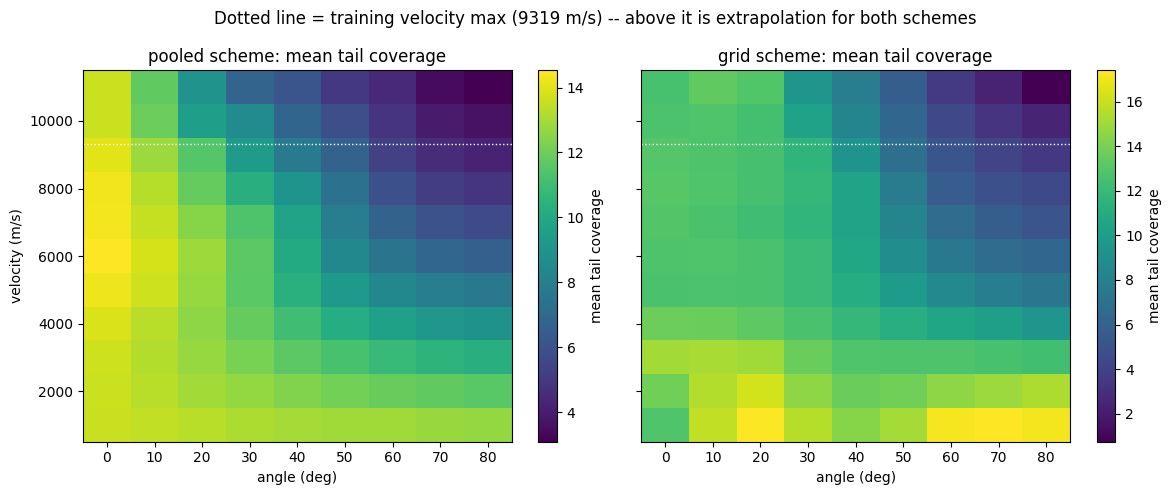

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, grid, title in zip(axes, [pooled_mean, grid_mean], ["pooled", "grid"]):
    im = ax.pcolormesh(SWEEP_ANGLES, SWEEP_VELOCITIES, grid, shading="auto", cmap="viridis")
    ax.axhline(TRAIN_VELOCITIES_MAX, color="white", linestyle=":", linewidth=1)
    ax.set_xlabel("angle (deg)")
    ax.set_title(f"{title} scheme: mean tail coverage")
    fig.colorbar(im, ax=ax, label="mean tail coverage")
axes[0].set_ylabel("velocity (m/s)")
fig.suptitle("Dotted line = training velocity max (9319 m/s) -- above it is extrapolation for both schemes")
plt.tight_layout(); plt.show()

## 11000 m/s extrapolation validation

`fragment_velocities_11000.h5` was never used in training (the training
grid tops out at ~9319 m/s) -- load it now and compare the real, binned
outcome frequencies directly against both models' predictions at that same
velocity. Unlike the training-grid files, this one only contains data at a
single angle (80 deg -- grazing incidence, the harshest/most
extrapolation-sensitive condition), not a full 0-80 sweep: it was captured
as one targeted out-of-sample validation point, not a full grid.

In [4]:
ANGLES_WITH_DATA = [80]   # fragment_velocities_11000.h5 only has this one angle's group

df_11000 = load_trajectories(str(RESULTS_PATH), str(FRAMES_PATH), [11000], ANGLES_WITH_DATA,
                              n_substrate_atoms=N_SUBSTRATE_ATOMS)
df_11000 = df_11000[df_11000["n_atoms"] <= 2].reset_index(drop=True)
real_velocity_11000 = float(df_11000["velocity"].unique()[0])
print(f"{len(df_11000)} held-out events at {real_velocity_11000:.1f} m/s (never used in training)")

10150 held-out events at 11000.0 m/s (never used in training)


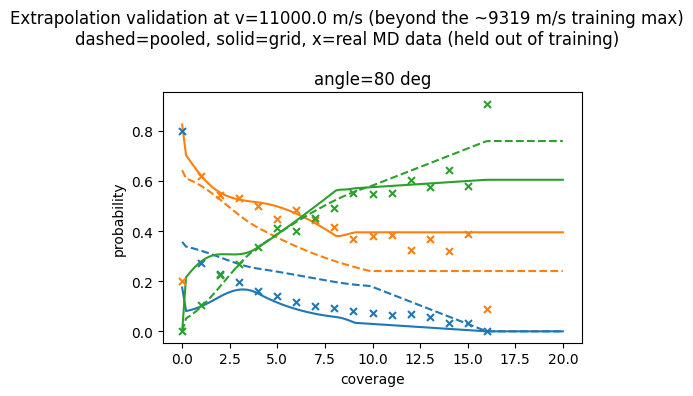

In [5]:
def bin_real(df, velocity, angle):
    sub = df[np.isclose(df["velocity"], velocity) & np.isclose(df["angle"], angle)]
    centers, probs = [], []
    for c in range(int(sub["coverage"].max()) + 1):
        m = sub[sub["coverage"] == c]
        if len(m) > 0:
            counts = m["n_atoms"].value_counts(normalize=True)
            probs.append([counts.get(0, 0.0), counts.get(1, 0.0), counts.get(2, 0.0)])
            centers.append(c)
    return np.array(centers), np.array(probs)


coverages_plot = np.linspace(0, 20, 100)
labels = ["p_ads", "p_O_des", "p_O2_des"]
colors = ["C0", "C1", "C2"]

fig, axes = plt.subplots(1, len(ANGLES_WITH_DATA), figsize=(5 * len(ANGLES_WITH_DATA), 4),
                          sharey=True, squeeze=False)
axes = axes[0]
for ax, angle in zip(axes, ANGLES_WITH_DATA):
    centers, real_probs = bin_real(df_11000, real_velocity_11000, angle)
    pooled_probs = np.array([pooled_model.probs(c, real_velocity_11000, angle) for c in coverages_plot])
    grid_probs = np.array([grid_model.eval(np.array([c]), [real_velocity_11000, angle]) for c in coverages_plot])
    for k in range(3):
        ax.plot(coverages_plot, pooled_probs[:, k], "--", color=colors[k])
        ax.plot(coverages_plot, grid_probs[:, k], "-", color=colors[k])
        ax.scatter(centers, real_probs[:, k], color=colors[k], marker="x", s=25, zorder=5)
    ax.set_title(f"angle={angle} deg")
    ax.set_xlabel("coverage")
axes[0].set_ylabel("probability")
fig.suptitle(f"Extrapolation validation at v={real_velocity_11000:.1f} m/s "
             f"(beyond the ~9319 m/s training max)\ndashed=pooled, solid=grid, x=real MD data (held out of training)")
plt.tight_layout(); plt.show()